# Random Variable Generation — the Acceptance–Rejection Method

The inverse transform method requires a closed-form $F^{-1}$. The **acceptance–rejection** method only requires the ability to sample from another distribution $g$ that resembles the target $f$.

Contents:
1. Principle of the method
2. $M \ge 1$
3. A case where the method is impossible: Cauchy from Gaussian
4. Proof that the method samples from $f$
5. Acceptance probability and mean number of trials
6. Application: the left-truncated Gaussian distribution

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erfc

np.random.seed(0)

---
## 1. Principle

- $f$: **target** density;
- $g$: **proposal** density, which we can sample from;
- $M$: constant such that $f(x) \le M\,g(x)$ for all $x$ (the curve $M g$ is an envelope above $f$).

**Algorithm:**
1. draw $X \sim g$ and $U \sim \mathcal{U}[0,1]$;
2. if $U \le \dfrac{f(X)}{M\,g(X)}$, accept $Y = X$; otherwise reject and start again.

Geometrically, the point $\big(X,\ U\,M g(X)\big)$ is uniform under the envelope $M g$, and it is accepted when it falls under $f$. The ratio $\frac{f(x)}{M g(x)} \in [0,1]$ is the acceptance probability of a proposal at $x$. The best constant is $M = \max_x f(x)/g(x)$.

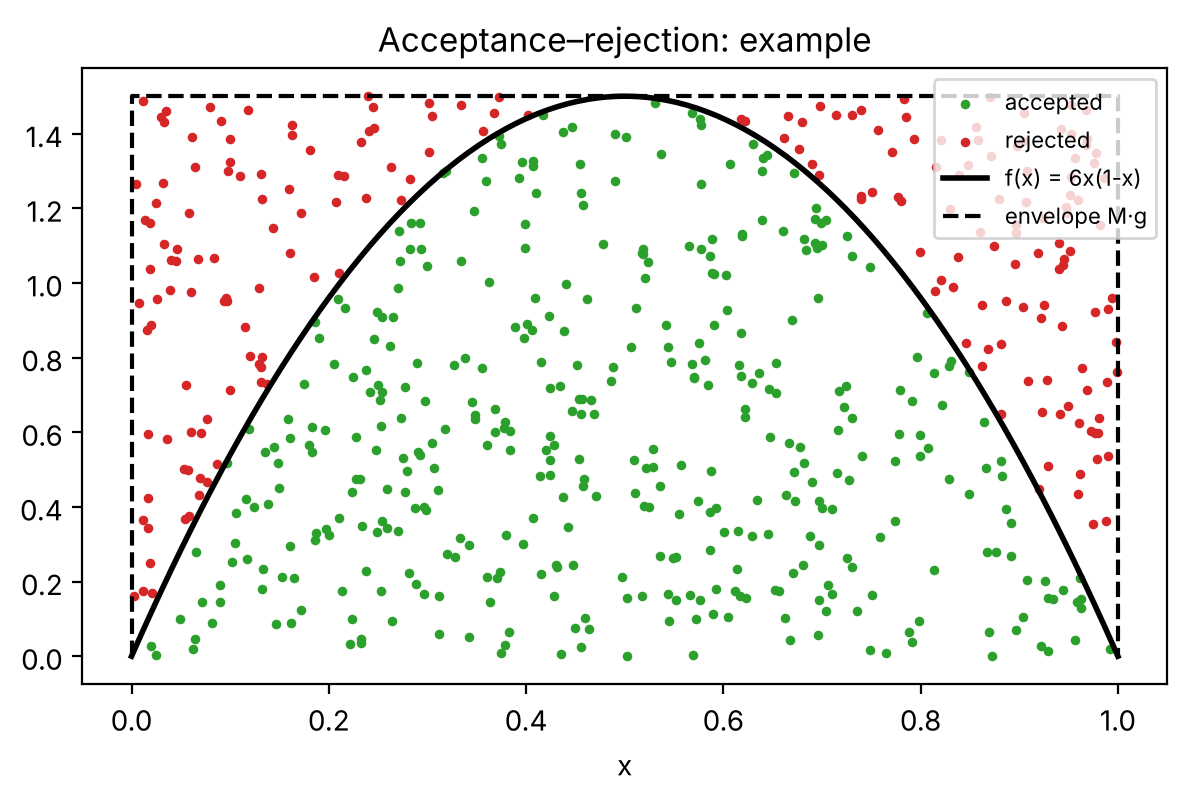

Acceptance rate: 0.662   (theoretical 1/M = 0.667)


In [2]:
# Example: f(x) = 6x(1-x) on [0,1], uniform proposal g = 1, M = max f/g = 1.5
f_ex = lambda x: 6 * x * (1 - x)
M_ex = 1.5
n = 600
X = np.random.rand(n)
U = np.random.rand(n)
height = U * M_ex
acc = height <= f_ex(X)

xx = np.linspace(0, 1, 200)
plt.figure(figsize=(7, 4))
plt.scatter(X[acc], height[acc], s=6, c="tab:green", label="accepted")
plt.scatter(X[~acc], height[~acc], s=6, c="tab:red", label="rejected")
plt.plot(xx, f_ex(xx), "k", lw=2, label="f(x) = 6x(1-x)")
plt.plot([0, 0, 1, 1], [0, M_ex, M_ex, 0], "k--", label="envelope M·g")
plt.legend(loc="upper right", fontsize=8); plt.xlabel("x")
plt.title("Acceptance–rejection: example")
plt.show()
print(f"Acceptance rate: {acc.mean():.3f}   (theoretical 1/M = {1/M_ex:.3f})")

---
## 2. $M \ge 1$

Integrating $f(x) \le M g(x)$ over $\mathbb{R}$, and using that densities integrate to 1:

$$1 = \int_{-\infty}^{+\infty} f(x)\,dx \le M\int_{-\infty}^{+\infty} g(x)\,dx = M \quad\Longrightarrow\quad \boxed{M \ge 1}$$

Equality $M = 1$ holds only when $f = g$.

---
## 3. Cauchy distribution from a Gaussian proposal

Target $f(x) = \dfrac{1}{\pi(1+x^2)}$, proposal $g(x) = \dfrac{1}{\sqrt{2\pi}}e^{-x^2/2}$. A valid $M$ requires $f(x)/g(x) \le M$ for all $x$. However

$$\frac{f(x)}{g(x)} = \frac{1}{\pi(1+x^2)}\cdot\frac{\sqrt{2\pi}}{e^{-x^2/2}} = \sqrt{\frac{2}{\pi}}\cdot\frac{e^{x^2/2}}{1+x^2} \xrightarrow[x\to\pm\infty]{} +\infty,$$

since the exponential grows faster than the polynomial. The ratio is unbounded, so **no constant $M$ exists**: the method cannot generate a Cauchy variable from a Gaussian proposal. The Cauchy distribution has heavy tails ($\sim 1/x^2$) while the Gaussian has light tails ($\sim e^{-x^2/2}$); the proposal must have tails at least as heavy as the target. (The converse works: $\mathcal{N}(0,1)$ from a Cauchy proposal with $M = \sqrt{2\pi/e} \approx 1.52$.)

x =  0   f(x)/g(x) = 7.979e-01
x =  1   f(x)/g(x) = 6.577e-01
x =  2   f(x)/g(x) = 1.179e+00
x =  3   f(x)/g(x) = 7.182e+00
x =  5   f(x)/g(x) = 8.235e+03
x = 10   f(x)/g(x) = 4.096e+19


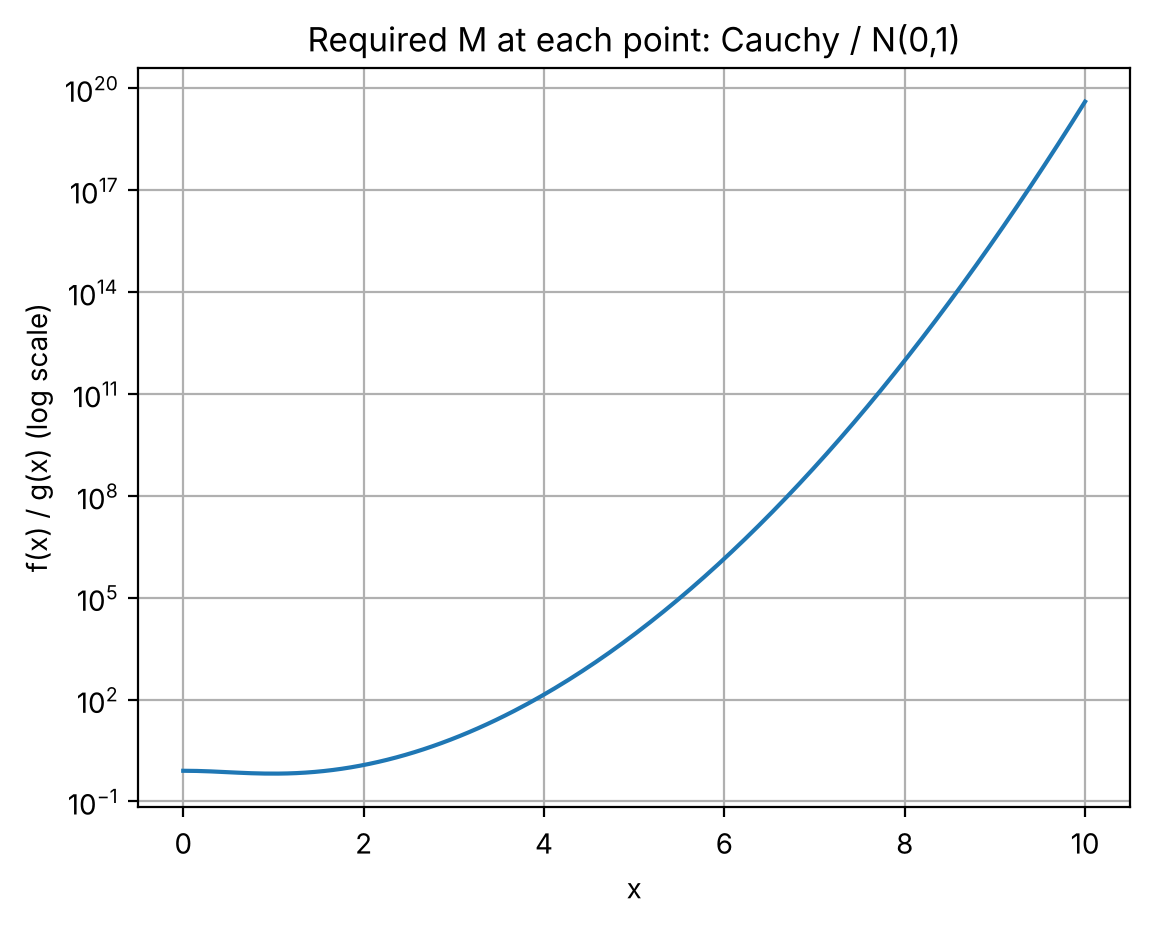

In [3]:
def f_cauchy(x):
    return 1 / (np.pi * (1 + x**2))

def g_normal(x):
    return np.exp(-x**2 / 2) / np.sqrt(2 * np.pi)

for x in [0, 1, 2, 3, 5, 10]:
    print(f"x = {x:2d}   f(x)/g(x) = {f_cauchy(x)/g_normal(x):.3e}")

x = np.linspace(0, 10, 200)
plt.semilogy(x, f_cauchy(x) / g_normal(x))
plt.xlabel("x"); plt.ylabel("f(x) / g(x) (log scale)")
plt.title("Required M at each point: Cauchy / N(0,1)")
plt.grid(True, which="both"); plt.show()

---
## 4. Correctness of the method

A trial $(X, U)$ is accepted if $U \le \frac{f(X)}{Mg(X)}$; trials are independent. Let $F_f(y) = \int_{-\infty}^y f(t)\,dt$.

**(a)** $\lbrace Y \le y\rbrace$ occurs if the first $i$ trials are rejected and trial $i+1$ is accepted with $X \le y$. Trials are independent (multiply) and the cases $i = 0, 1, \dots$ are disjoint (add):

$$P(Y \le y) = \sum_{i=0}^{+\infty} P\!\left(X \le y,\ U \le \frac{f(X)}{Mg(X)}\right)\left[P\!\left(U \ge \frac{f(X)}{Mg(X)}\right)\right]^i$$

**(b)** Conditioning on $X = x$, $P\big(U \le \frac{f(x)}{Mg(x)}\big) = \frac{f(x)}{Mg(x)}$. Integrating over $x \le y$ with weight $g(x)$:

$$P\!\left(X \le y,\ U \le \frac{f(X)}{Mg(X)}\right) = \int_{-\infty}^{y} g(x)\,\frac{f(x)}{M\,g(x)}\,dx = \frac{1}{M}\int_{-\infty}^{y} f(x)\,dx = \frac{1}{M}F_f(y)$$

With $y \to +\infty$: $P(\text{accept}) = 1/M$ and $q = P(\text{reject}) = 1 - 1/M$.

**(c)** Substituting into (a) and summing the geometric series:

$$P(Y \le y) = \frac{F_f(y)}{M}\sum_{i=0}^{+\infty} q^i = \frac{F_f(y)}{M}\cdot\frac{1}{1-q} = \frac{F_f(y)}{M}\cdot M = \boxed{F_f(y)}$$

so $Y$ has density $f$.

---
## 5. Acceptance probability and mean number of trials

The acceptance probability is $p = 1/M$. Let $N$ be the number of trials until the first acceptance. Conditioning on the first trial:

$$E[N] = 1 + q\,E[N] \quad\Longrightarrow\quad \boxed{E[N] = \frac{1}{1-q} = M}$$

The cost of the method is $M$ trials per sample on average, so the proposal $g$ should be as close as possible to $f$ (including its tails) to make $M$ close to 1.

In [4]:
def sample_example():
    n = 0
    while True:
        n += 1
        X, U = np.random.rand(), np.random.rand()
        if U <= f_ex(X) / M_ex:
            return X, n

N_ex = [sample_example()[1] for _ in range(10000)]
print(f"Mean number of trials: {np.mean(N_ex):.3f}   (theoretical M = {M_ex})")

Mean number of trials: 1.516   (theoretical M = 1.5)


---
## 6. Application: left-truncated Gaussian

Target: $\mathcal{N}(0,1)$ restricted to $[s, +\infty)$. We use

$$\mathrm{erfc}(x) = \frac{2}{\sqrt{\pi}}\int_x^{\infty} e^{-u^2}\,du.$$

### 6.1 Naive method

Draw $X \sim \mathcal{N}(0,1)$; accept if $X \ge s$, otherwise retry. The resulting density is $f(y) = \alpha\,\mathbf{1}_{y\ge s}\,e^{-y^2/2}$.

**Normalizing constant.** With the change of variable $u = y/\sqrt2$ ($dy = \sqrt2\,du$):

$$\int_{s}^{\infty} e^{-y^2/2}\,dy = \sqrt2\int_{s/\sqrt2}^{\infty} e^{-u^2}\,du = \sqrt{\frac{\pi}{2}}\,\mathrm{erfc}\!\left(\frac{s}{\sqrt2}\right)
\quad\Longrightarrow\quad
\boxed{\alpha = \sqrt{\frac{2}{\pi}}\,\frac{1}{\mathrm{erfc}(s/\sqrt2)}}$$

**Acceptance probability and mean number of trials.**

$$P(X \ge s) = \frac{1}{\sqrt{2\pi}}\int_{s}^{\infty} e^{-y^2/2}\,dy = \frac12\,\mathrm{erfc}\!\left(\frac{s}{\sqrt2}\right) = M_1^{-1}, \qquad E[N] = M_1 = \frac{2}{\mathrm{erfc}(s/\sqrt2)}$$

In [5]:
for s in [0, 1, 2, 3, 4]:
    p = 0.5 * erfc(s / np.sqrt(2))
    print(f"s = {s}:  P(accept) = {p:.6f}   M1 = {1/p:,.1f}")

s = 0:  P(accept) = 0.500000   M1 = 2.0
s = 1:  P(accept) = 0.158655   M1 = 6.3
s = 2:  P(accept) = 0.022750   M1 = 44.0
s = 3:  P(accept) = 0.001350   M1 = 740.8
s = 4:  P(accept) = 0.000032   M1 = 31,574.4


For large $s$ almost every draw is rejected and $M_1$ explodes.

### 6.2 Acceptance–rejection with a shifted exponential proposal

Proposal: $g(x) = \mathbf{1}_{x\ge s}\,\lambda\,e^{-\lambda(x-s)}$, which lives only to the right of $s$ and decays like the Gaussian tail.

**Sampling from $g$.** $X = s - \lambda^{-1}\ln U = s + E$ with $E = -\ln U/\lambda \sim \mathcal{E}(\lambda)$ (inverse transform, since $1-U$ is also uniform). For $x \ge s$:

$$P(X > x) = P(E > x - s) = e^{-\lambda(x-s)} \;\Longrightarrow\; g(x) = \frac{d}{dx}\left(1 - e^{-\lambda(x-s)}\right) = \lambda e^{-\lambda(x-s)}.$$

**Bound on $f/g$.** For $x \ge s$:

$$\frac{f(x)}{g(x)} = \frac{\alpha}{\lambda}\,e^{\,h(x) - \lambda s}, \qquad h(x) = -\frac{x^2}{2} + \lambda x.$$

$h'(x) = -x + \lambda = 0$ at $x = \lambda$, where $h$ reaches its maximum $h(\lambda) = \lambda^2/2$. Hence

$$\boxed{\frac{f(x)}{g(x)} \le M_2 = \frac{\alpha}{\lambda}\exp\!\left(\frac{\lambda^2}{2} - \lambda s\right)}$$

**Optimal $\lambda$.** Minimizing $\ln M_2 = \ln\alpha - \ln\lambda + \frac{\lambda^2}{2} - \lambda s$:

$$-\frac{1}{\lambda} + \lambda - s = 0 \iff \lambda^2 - s\lambda - 1 = 0 \quad\Longrightarrow\quad \boxed{\lambda^* = \frac{s + \sqrt{s^2+4}}{2}}$$

(the positive root). Using $\lambda^{*2} = s\lambda^* + 1$:

$$\boxed{M_2^* = \frac{\alpha}{\lambda^*}\exp\!\left(\frac{1 - \lambda^* s}{2}\right)}$$

### 6.3 Comparison of $M_1$ and $M_2^*$

s = -1:  M1 =      1.189   M2* = 1.723
s =  0:  M1 =      2.000   M2* = 1.315
s =  1:  M1 =      6.303   M2* = 1.141
s =  2:  M1 =     43.956   M2* = 1.071
s =  3:  M1 =    740.797   M2* = 1.041
s =  4:  M1 =  31574.386   M2* = 1.026

Threshold (M1 = M2*): s ≈ -0.47


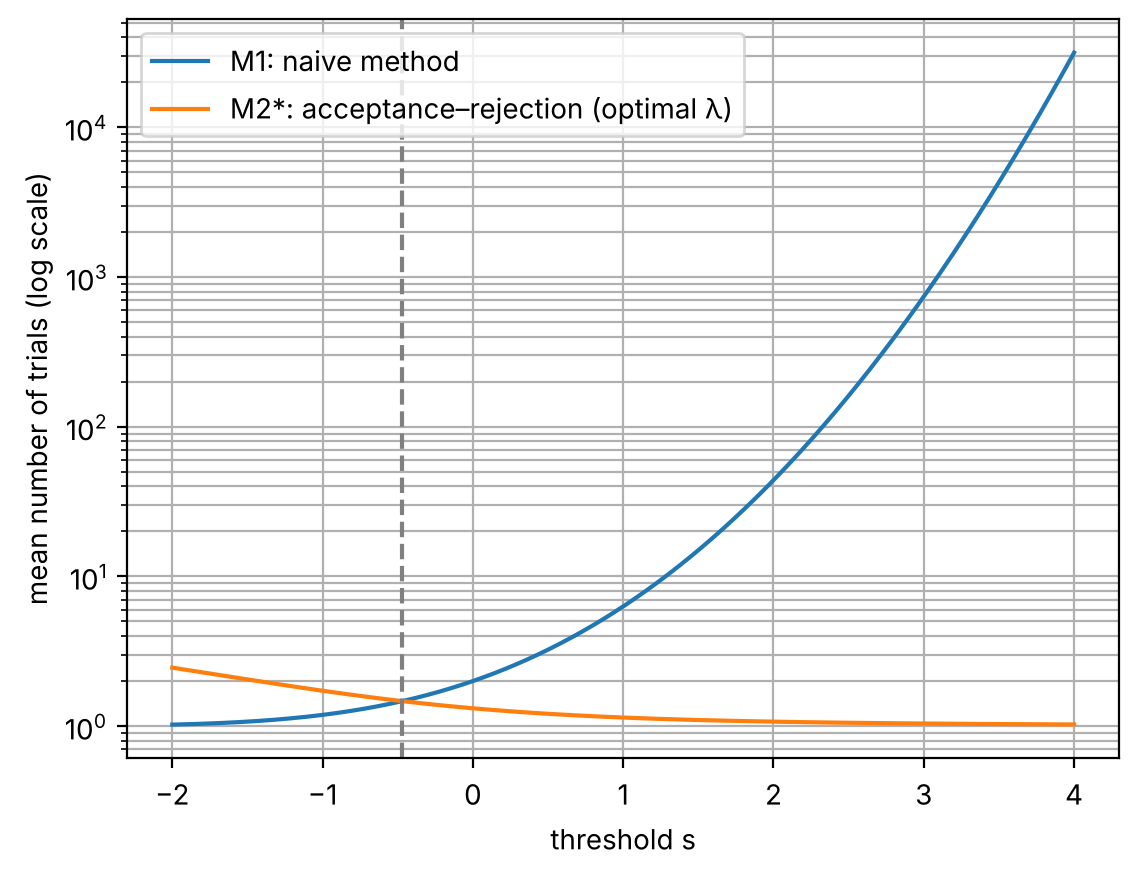

In [6]:
def M1(s):
    return 2 / erfc(s / np.sqrt(2))

def M2(s):
    lam = (s + np.sqrt(s**2 + 4)) / 2
    alpha = np.sqrt(2 / np.pi) / erfc(s / np.sqrt(2))
    return alpha / lam * np.exp((1 - lam * s) / 2)

for s in [-1, 0, 1, 2, 3, 4]:
    print(f"s = {s:2d}:  M1 = {M1(s):>10.3f}   M2* = {M2(s):.3f}")

s_grid = np.linspace(-2, 4, 2001)
idx = np.argmin(np.abs(M1(s_grid) - M2(s_grid)))
print(f"\nThreshold (M1 = M2*): s ≈ {s_grid[idx]:.2f}")

plt.semilogy(s_grid, M1(s_grid), label="M1: naive method")
plt.semilogy(s_grid, M2(s_grid), label="M2*: acceptance–rejection (optimal λ)")
plt.axvline(s_grid[idx], color="gray", ls="--")
plt.xlabel("threshold s"); plt.ylabel("mean number of trials (log scale)")
plt.legend(); plt.grid(True, which="both"); plt.show()

$M_1$ grows very fast with $s$ while $M_2^*$ stays close to 1. Above the crossing point, the acceptance–rejection method with the shifted exponential proposal requires fewer trials; for very negative $s$ almost the whole bell is kept and the naive method is better.

### 6.4 Simulation for $s = 1$

lambda* = 1.6180
Method 1: mean trials = 6.310   theoretical M1  = 6.303
Method 2: mean trials = 1.139   theoretical M2* = 1.141


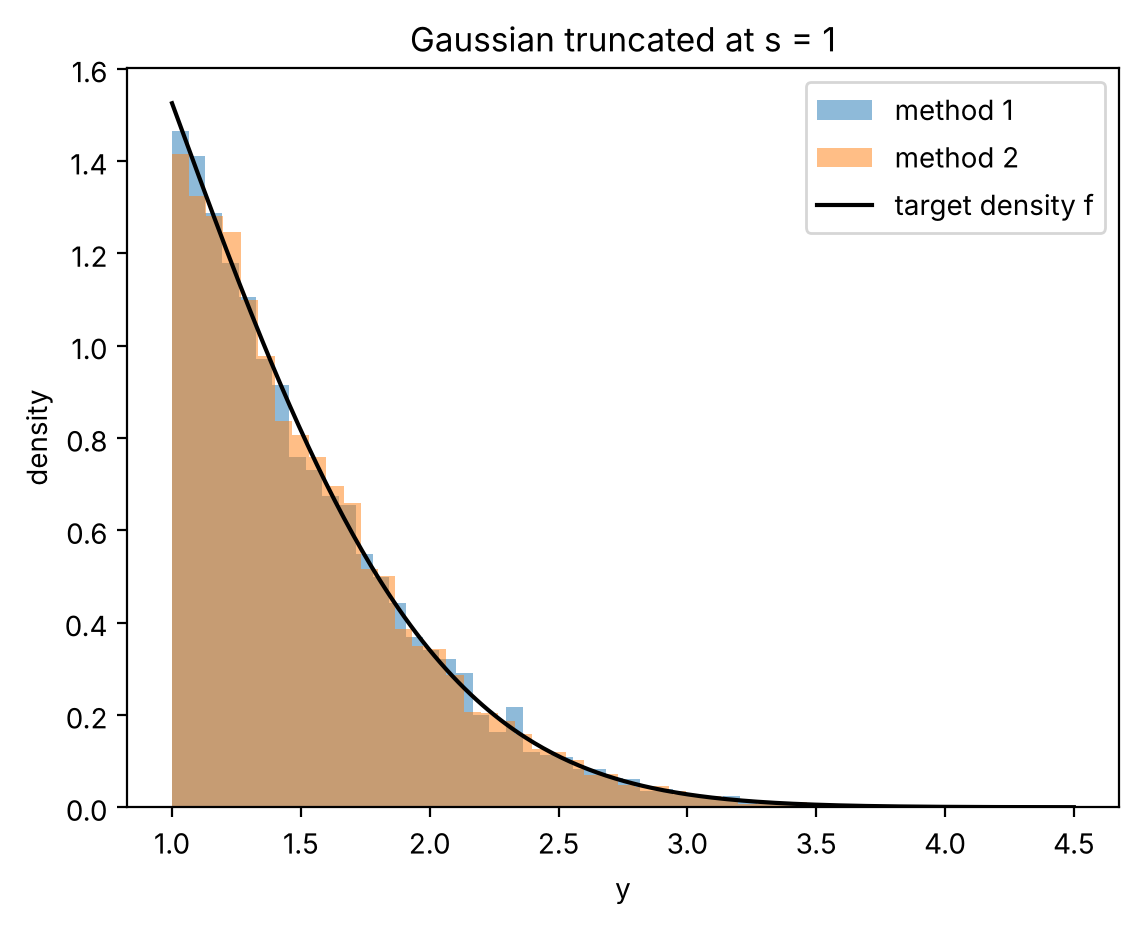

In [7]:
s = 1
T = 10000

lam = (s + np.sqrt(s**2 + 4)) / 2
alpha = np.sqrt(2 / np.pi) / erfc(s / np.sqrt(2))
M2_s = M2(s)

def f(x):
    return alpha * np.exp(-x**2 / 2)

def g(x):
    return lam * np.exp(-lam * (x - s))

def method1():
    n = 0
    while True:
        n += 1
        X = np.random.randn()
        if X >= s:
            return X, n

def method2():
    n = 0
    while True:
        n += 1
        X = s - np.log(np.random.rand()) / lam
        U = np.random.rand()
        if U <= f(X) / (M2_s * g(X)):
            return X, n

Y1 = np.zeros(T); N1 = np.zeros(T)
Y2 = np.zeros(T); N2 = np.zeros(T)
for k in range(T):
    Y1[k], N1[k] = method1()
    Y2[k], N2[k] = method2()

print(f"lambda* = {lam:.4f}")
print(f"Method 1: mean trials = {np.mean(N1):.3f}   theoretical M1  = {M1(s):.3f}")
print(f"Method 2: mean trials = {np.mean(N2):.3f}   theoretical M2* = {M2_s:.3f}")

y = np.linspace(s, 4.5, 300)
plt.hist(Y1, bins=50, density=True, alpha=0.5, label="method 1")
plt.hist(Y2, bins=50, density=True, alpha=0.5, label="method 2")
plt.plot(y, f(y), "k", label="target density f")
plt.xlabel("y"); plt.ylabel("density")
plt.title("Gaussian truncated at s = 1")
plt.legend(); plt.show()

Both methods produce the same distribution (both histograms follow $f$), and the observed mean numbers of trials agree with $M_1$ and $M_2^*$. The shifted exponential proposal requires several times fewer trials.

---
## Conclusion

- Acceptance–rejection samples from any density $f$ given a proposal $g$ and a constant $M$ with $f \le M g$; it is exact and costs $M$ trials per sample on average.
- The proposal must have tails at least as heavy as the target, and should be close to $f$ so that $M$ is close to 1.
- For the truncated Gaussian, the naive method becomes impractical for large $s$, while the shifted exponential proposal with optimal $\lambda^*$ keeps $M_2^* \approx 1$.